## §0  Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch as th

from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import VecNormalize
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.evaluation import evaluate_policy

from environment import AssetVecEnv, AssetEnvState, AssetEpisodeLog, log_to_dataframe
from preprocessing import preprocess, INDICATORS
from rainbow_dqn import StickyDQN, DuelingDQNPolicy
from discrete_critic import StickyDQN as StickyDQN_
from replay_buffer import PrioritizedReplayBuffer, LambdaReplayBuffer
from backtest import price_series_from_env, infer_periods, activity_to_equity, activity_to_returns, metrics

In [2]:
# ── load & preprocess ─────────────────────────────────────────────────────────
df = preprocess()

dates = pd.to_datetime(df["date"])
print(f"Total bars: {len(df)}  ({dates.iloc[0].date()} → {dates.iloc[-1].date()})")

Data shape: (65989, 7)
Date range: 2017-12-31 23:00:00 -> 2025-07-17 13:00:00
Processed shape: (65989, 93)
Indicators (86): ['volume_adi', 'volume_obv', 'volume_cmf', 'volume_fi', 'volume_em', 'volume_sma_em', 'volume_vpt', 'volume_vwap', 'volume_mfi', 'volume_nvi', 'volatility_bbm', 'volatility_bbh', 'volatility_bbl', 'volatility_bbw', 'volatility_bbp', 'volatility_bbhi', 'volatility_bbli', 'volatility_kcc', 'volatility_kch', 'volatility_kcl', 'volatility_kcw', 'volatility_kcp', 'volatility_kchi', 'volatility_kcli', 'volatility_dcl', 'volatility_dch', 'volatility_dcm', 'volatility_dcw', 'volatility_dcp', 'volatility_atr', 'volatility_ui', 'trend_macd', 'trend_macd_signal', 'trend_macd_diff', 'trend_sma_fast', 'trend_sma_slow', 'trend_ema_fast', 'trend_ema_slow', 'trend_vortex_ind_pos', 'trend_vortex_ind_neg', 'trend_vortex_ind_diff', 'trend_trix', 'trend_mass_index', 'trend_dpo', 'trend_kst', 'trend_kst_sig', 'trend_kst_diff', 'trend_ichimoku_conv', 'trend_ichimoku_base', 'trend_ichim

In [3]:
# ── train / val split — 18 months train, 6 months val ────────────────────────
TRAIN_MONTHS = 18
VAL_MONTHS   = 6

t0        = dates.iloc[0]
train_end = t0        + pd.DateOffset(months=TRAIN_MONTHS)
val_end   = train_end + pd.DateOffset(months=VAL_MONTHS)

mask_train = dates <  train_end
mask_val   = (dates >= train_end) & (dates < val_end)

for name, mask in [("train", mask_train), ("val", mask_val)]:
    d = dates[mask]
    print(f"{name:5s}  bars={mask.sum():6d}  {d.iloc[0].date()} → {d.iloc[-1].date()}")

# ── environment factory ───────────────────────────────────────────────────────
ENV_KWARGS = dict(
    initial_cash     = 10_000.0,
    commission_rate  = 1e-3,
    max_leverage     = 1.0,
    allow_shorts     = True,
)

def make_config(sub_df):
    return {
        "price_array": sub_df["close"].values.astype(np.float32),
        "tech_array":  sub_df[INDICATORS].values.astype(np.float32),
        "date":        pd.to_datetime(sub_df["date"]),
    }

train_env = AssetVecEnv(make_config(df[mask_train].reset_index(drop=True)), 
                        n_envs=1, 
                        # episode_len = 1000,
                        **ENV_KWARGS)
val_env   = AssetVecEnv(make_config(df[mask_val  ].reset_index(drop=True)), 
                        n_envs=1, 
                        **ENV_KWARGS)

print(f"\ntrain T={train_env.T}  val T={val_env.T}")

train  bars= 13026  2017-12-31 → 2019-06-30
val    bars=  4380  2019-06-30 → 2019-12-30

train T=13026  val T=4380


## §1  Optuna gridsearch

## Optuna gridsearch — notes

**Objective:** val net return `r = total_asset / initial_cash − 1` after one deterministic rollout on the 6-month val window. Maximised.

**Protocol:** Stage 1 — single seed, ASHA pruner (rungs at epoch 10 → 30 → 40).  Stage 2 — top configs retrained with 5 seeds, median return, no pruning.

**VecNormalize sync:** `norm_val.obs_rms = norm_train.obs_rms` before every val rollout — critical, otherwise val obs are unnormalised.

**Retrain winner:**
```python
StickyDQN(env=norm_train, **best_params_to_kwargs(study.best_params), **DEFAULT_KWARGS, gradient_steps=20, seed=42)
```

In [4]:
# ── training constants ────────────────────────────────────────────────────────
N_ENVS        = 16
EPISODE_LEN   = None     # full 13 026-bar training episodes

EPOCH_STEPS   = 13_026   # one training-data equivalent per epoch
MAX_EPOCHS    = 40
STAGE1_SEED   = 42

N_SEEDS       = 5
SEEDS         = list(range(N_SEEDS))

TRAIN_FREQ    = 168                          # 1 week hourly bars
NEW_TRANS     = TRAIN_FREQ * N_ENVS         # 2 688 new transitions per train call

# ── fixed hyperparameters ─────────────────────────────────────────────────────
DEFAULT_KWARGS = dict(
    policy                  = "MlpPolicy",
    buffer_size             = 100_000,
    replay_buffer_class     = PrioritizedReplayBuffer,
    learning_starts         = TRAIN_FREQ,    # start after one full train_freq window
    tau                     = 1.0,
    train_freq              = TRAIN_FREQ,
    exploration_initial_eps = 1.0,
    exploration_final_eps   = 0.05,
    gamma                   = 0.999,
    policy_kwargs           = dict(net_arch=[64, 64]),
    verbose                 = 0,
    # gradient_steps, batch_size, replay_buffer_kwargs — tunable, built in _build_model
)

print(f"NEW_TRANS per train call : {NEW_TRANS}")
print(f"Max env steps per trial  : {EPOCH_STEPS * MAX_EPOCHS:,}")
print(f"ASHA rungs               : epoch 10 → 30 → {MAX_EPOCHS}")


NEW_TRANS per train call : 2688
Max env steps per trial  : 521,040
ASHA rungs               : epoch 10 → 30 → 40


In [5]:
# ── optuna: env factory + model builder + objective (Stage 1 — ASHA) ──────────
import optuna, time
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)


def _make_envs():
    train_raw = AssetVecEnv(
        make_config(df[mask_train].reset_index(drop=True)),
        n_envs=N_ENVS, episode_len=EPISODE_LEN, **ENV_KWARGS,
    )
    val_raw = AssetVecEnv(
        make_config(df[mask_val].reset_index(drop=True)),
        n_envs=1, **ENV_KWARGS,
    )
    return (VecNormalize(train_raw, norm_reward=False),
            VecNormalize(val_raw,   norm_reward=False, training=False))


def _batch_size(gradient_steps: int, replay_ratio: float) -> int:
    """batch_size derived from replay ratio to keep ratio = gs*bs / NEW_TRANS."""
    bs = int(replay_ratio * NEW_TRANS / gradient_steps)
    bs = max(32, (bs // 32) * 32)   # round down to nearest 32, floor at 32
    return bs


def _build_model(trial, norm_train_env, seed):
    # ── coupled: gradient_steps + replay_ratio → batch_size ──────────────────
    gradient_steps = trial.suggest_int("gradient_steps",   5,  64, log=True)
    replay_ratio   = trial.suggest_float("replay_ratio",   0.5, 4.0)
    batch_size     = _batch_size(gradient_steps, replay_ratio)
    trial.set_user_attr("batch_size", batch_size)   # store derived value

    # ── PER kwargs ────────────────────────────────────────────────────────────
    n_steps       = trial.suggest_int("n_steps",       1,   10)
    total_samples = trial.suggest_int("total_samples", 50_000, 2_000_000, log=True)

    return StickyDQN(
        env                     = norm_train_env,
        # ── tunable ──────────────────────────────────────────────────────────
        learning_rate           = trial.suggest_float("learning_rate",         1e-5, 1e-3, log=True),
        target_update_interval  = trial.suggest_int("target_update_interval",  500,  5_000, log=True),
        exploration_fraction    = trial.suggest_float("exploration_fraction",   0.2,  0.8),
        mean_hold               = trial.suggest_int("mean_hold",               10,   200),
        switching_cost          = trial.suggest_float("switching_cost",        1e-3,  0.2, log=True),
        gradient_steps          = gradient_steps,
        batch_size              = batch_size,
        replay_buffer_kwargs    = dict(n_steps=n_steps, total_samples=total_samples),
        # ── fixed ────────────────────────────────────────────────────────────
        **DEFAULT_KWARGS,
        seed                    = seed,
    )


def best_params_to_kwargs(params: dict) -> dict:
    """Convert study.best_params → StickyDQN constructor kwargs.

    replay_ratio is a search artifact — converted to batch_size.
    n_steps / total_samples are packed into replay_buffer_kwargs.
    All other keys match StickyDQN exactly.
    """
    gs    = params["gradient_steps"]
    ratio = params["replay_ratio"]
    kwargs = dict(
        gradient_steps       = gs,
        batch_size           = _batch_size(gs, ratio),
        replay_buffer_kwargs = dict(
            n_steps       = params["n_steps"],
            total_samples = params["total_samples"],
        ),
    )
    for k in ("learning_rate", "target_update_interval", "exploration_fraction",
              "mean_hold", "switching_cost"):
        kwargs[k] = params[k]
    return kwargs


def _val_return(model, norm_train, norm_val):
    norm_val.obs_rms = norm_train.obs_rms
    obs  = norm_val.reset()
    done = np.array([False])
    while not done[0]:
        action, _ = model.predict(obs, deterministic=True)
        obs, _, done, infos = norm_val.step(action)
    return infos[0]["episode"]["r"]


def objective(trial):
    t0 = time.perf_counter()
    norm_train, norm_val = _make_envs()
    model = _build_model(trial, norm_train, seed=STAGE1_SEED)

    for epoch in range(1, MAX_EPOCHS + 1):
        model.learn(
            total_timesteps     = EPOCH_STEPS,
            reset_num_timesteps = (epoch == 1),
            progress_bar        = False,
        )
        r       = _val_return(model, norm_train, norm_val)
        elapsed = time.perf_counter() - t0

        if epoch == 1:
            p  = trial.params
            bs = trial.user_attrs["batch_size"]
            print(f"\n trial #{trial.number:>3d} │ "
                  f"lr={p['learning_rate']:.1e}  "
                  f"gs={p['gradient_steps']}  bs={bs}  ratio={p['replay_ratio']:.1f}  "
                  f"n_steps={p['n_steps']}  tot_s={p['total_samples']:.0e}\n"
                  f"           │ tgt={p['target_update_interval']}  "
                  f"expl={p['exploration_fraction']:.2f}  "
                  f"hold={p['mean_hold']}  sw={p['switching_cost']:.3f}")

        print(f"  epoch {epoch:>2d}/{MAX_EPOCHS}  r={r:+.4f}  ({elapsed:.0f}s)")

        trial.report(r, step=epoch)
        if trial.should_prune():
            print("  → PRUNED")
            raise optuna.exceptions.TrialPruned()

    print(f"  ✓ done  final_r={r:+.4f}  ({time.perf_counter()-t0:.0f}s)")
    return r


print("Stage 1 objective ready.")
print("Retrain:  StickyDQN(env=..., **best_params_to_kwargs(study.best_params), **DEFAULT_KWARGS)")


Stage 1 objective ready.
Retrain:  StickyDQN(env=..., **best_params_to_kwargs(study.best_params), **DEFAULT_KWARGS)


In [6]:
# ── Stage 1 study — ASHA / Hyperband ─────────────────────────────────────────
study = optuna.create_study(
    direction      = "maximize",
    study_name     = "stage1_sticky_dqn_eth",
    storage        = "sqlite:///optuna_stage1.db",
    load_if_exists = True,
    sampler        = TPESampler(seed=0, n_startup_trials=20, multivariate=True),
    pruner         = optuna.pruners.HyperbandPruner(
                         min_resource     = 10,    # prune no earlier than epoch 10
                         max_resource     = MAX_EPOCHS,
                         reduction_factor = 3,     # rungs: 10 → 30 → 40
                     ),
)

study.optimize(objective, n_trials=200, show_progress_bar=True)

# ── results ───────────────────────────────────────────────────────────────────
best = study.best_trial
print(f"\nBest trial #{best.number}  val_return={best.value:.4f}")
print(pd.Series(best.params).to_string())


/tmp/ipykernel_467580/2434026321.py:7: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler        = TPESampler(seed=0, n_startup_trials=20, multivariate=True),


  0%|          | 0/200 [00:00<?, ?it/s]


 trial #  1 │ lr=7.0e-05  gs=19  bs=416  ratio=3.0  n_steps=7  tot_s=4e+05
           │ tgt=2212  expl=0.46  hold=180  sw=0.165
  epoch  1/40  r=-0.5477  (8s)
  epoch  2/40  r=-0.5477  (9s)
  epoch  3/40  r=-0.9455  (10s)
  epoch  4/40  r=-0.9164  (11s)
  epoch  5/40  r=-0.9768  (11s)
  epoch  6/40  r=-0.9870  (12s)
  epoch  7/40  r=-0.9819  (13s)
  epoch  8/40  r=-0.9733  (14s)
  epoch  9/40  r=-0.9874  (14s)
  epoch 10/40  r=-0.9858  (15s)
  epoch 11/40  r=-0.9940  (16s)
  epoch 12/40  r=-0.9963  (17s)
  epoch 13/40  r=-0.9964  (17s)
  epoch 14/40  r=-0.9977  (18s)
  epoch 15/40  r=-0.9823  (19s)
  epoch 16/40  r=-0.8760  (20s)
  epoch 17/40  r=-0.7111  (20s)
  epoch 18/40  r=-0.6245  (21s)
  epoch 19/40  r=-0.5656  (22s)
  epoch 20/40  r=-0.5494  (23s)
  epoch 21/40  r=-0.5477  (23s)
  epoch 22/40  r=-0.5477  (24s)
  epoch 23/40  r=-0.5477  (25s)
  epoch 24/40  r=-0.5554  (26s)
  epoch 25/40  r=-0.5815  (26s)
  epoch 26/40  r=-0.6085  (27s)
  epoch 27/40  r=-0.6743  (28s)
  epoch 2

## §1.5  Stage 2 — seed robustness & statistical ranking

In [ ]:
# ── Stage 2: load Stage 1 study, extract top-10 complete trials ───────────────
from scipy import stats

stage1 = optuna.load_study(
    study_name = "stage1_sticky_dqn_eth",
    storage    = "sqlite:///optuna_stage1.db",
)

complete = [t for t in stage1.trials if t.state.name == "COMPLETE"]
top10    = sorted(complete, key=lambda t: t.value, reverse=True)[:10]

print(f"Stage 1: {len(stage1.trials)} trials  |  {len(complete)} complete\n")
rows = []
for rank, t in enumerate(top10, 1):
    bs = _batch_size(t.params["gradient_steps"], t.params["replay_ratio"])
    rows.append({"rank": rank, "trial": t.number, "stage1_r": round(t.value, 4),
                 "batch_size": bs, **t.params})
pd.DataFrame(rows).set_index("rank")


In [ ]:
# ── Stage 2: train each top-10 config with N_STAGE2_SEEDS seeds ───────────────
N_STAGE2_SEEDS       = 20
STAGE2_SEEDS         = list(range(N_STAGE2_SEEDS))
STAGE2_TIMESTEPS     = EPOCH_STEPS * MAX_EPOCHS    # full training, same as Stage 1 max

stage2_results = {}   # {trial_number: [val_returns over seeds]}

for rank, trial in enumerate(top10, 1):
    returns = []
    t0      = time.perf_counter()
    kw      = best_params_to_kwargs(trial.params)
    print(f"\n── rank {rank:>2d}  trial #{trial.number}  stage1_r={trial.value:.4f}")
    print(f"   gs={trial.params['gradient_steps']}  bs={_batch_size(trial.params['gradient_steps'], trial.params['replay_ratio'])}  "
          f"n_steps={trial.params['n_steps']}  lr={trial.params['learning_rate']:.1e}  "
          f"hold={trial.params['mean_hold']}  sw={trial.params['switching_cost']:.3f}")

    for seed in STAGE2_SEEDS:
        norm_train, norm_val = _make_envs()
        model = StickyDQN(
            env  = norm_train,
            **kw,
            **DEFAULT_KWARGS,
            seed = seed,
        )
        model.learn(total_timesteps=STAGE2_TIMESTEPS, reset_num_timesteps=True, progress_bar=False)
        r = _val_return(model, norm_train, norm_val)
        returns.append(r)
        print(f"  seed={seed:>2d}  r={r:+.4f}  running_median={np.median(returns):+.4f}")

    stage2_results[trial.number] = returns
    elapsed = time.perf_counter() - t0
    print(f"  ✓  median={np.median(returns):+.4f}  std={np.std(returns):.4f}  ({elapsed:.0f}s)")


In [ ]:
# ── Stage 2: statistical ranking ──────────────────────────────────────────────
trial_nums  = [t.number for t in top10]
all_returns = [stage2_results[n] for n in trial_nums]

# ── Kruskal-Wallis: any significant difference across configs? ────────────────
h_stat, p_kw = stats.kruskal(*all_returns)
print(f"Kruskal-Wallis  H={h_stat:.2f}  p={p_kw:.4f}")
print("  → significant differences exist" if p_kw < 0.05 else
      "  → no significant differences — configs may be statistically equivalent")

# ── Rank by median ────────────────────────────────────────────────────────────
medians    = {n: np.median(stage2_results[n]) for n in trial_nums}
ranked_ids = sorted(medians, key=medians.get, reverse=True)
best_num   = ranked_ids[0]

# ── Mann-Whitney U: each config vs best, one-sided (best > other) ─────────────
alpha      = 0.05
n_tests    = len(top10) - 1
alpha_corr = alpha / n_tests if n_tests else alpha    # Bonferroni correction

print(f"\nMann-Whitney U  (one-sided: best > other)  α={alpha_corr:.4f} (Bonferroni × {n_tests})")
print(f"{'rank':>4}  {'trial':>6}  {'median':>8}  {'std':>7}  {'U':>7}  {'p':>8}  sig")
print("─" * 60)

summary_rows = []
for rank, num in enumerate(ranked_ids, 1):
    med = medians[num]
    std = np.std(stage2_results[num])
    if num == best_num:
        print(f"{rank:>4}  #{num:<5}  {med:>+8.4f}  {std:>7.4f}  {'—':>7}  {'—':>8}  ← best")
        summary_rows.append(dict(rank=rank, trial=num, median=med, std=std, U=None, p=None, sig="best"))
    else:
        u, p = stats.mannwhitneyu(
            stage2_results[best_num], stage2_results[num], alternative="greater"
        )
        sig = "**" if p < alpha_corr else ("*" if p < alpha else "ns")
        print(f"{rank:>4}  #{num:<5}  {med:>+8.4f}  {std:>7.4f}  {u:>7.0f}  {p:>8.4f}  {sig}")
        summary_rows.append(dict(rank=rank, trial=num, median=med, std=std, U=u, p=round(p,4), sig=sig))

best_trial  = next(t for t in top10 if t.number == best_num)
print(f"\nStage 2 winner: trial #{best_num}  median={medians[best_num]:+.4f}")
print(f"  ** = p<{alpha_corr:.4f} (Bonferroni)  * = p<{alpha}  ns = not significant")


In [ ]:
# ── Stage 2: distribution plot ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ordered_ids = [t.number for t in top10]   # original stage1 ranking left→right
data        = [stage2_results[n] for n in ordered_ids]
labels      = [f"#{t.number}\ns1={t.value:.2f}" for t in top10]
colors      = ["steelblue" if t.number != best_num else "darkorange" for t in top10]

bp = ax.boxplot(data, labels=labels, patch_artist=True, medianprops=dict(color="black", lw=2))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(0, color="gray", linestyle="--", lw=0.8, label="break-even")
ax.set_xlabel("Trial  (stage1 val return in subtitle)")
ax.set_ylabel(f"Val return  ({N_STAGE2_SEEDS} seeds)")
ax.set_title(f"Stage 2 — seed robustness: top-10 Stage 1 configs × {N_STAGE2_SEEDS} seeds  |  orange = Stage 2 winner")
ax.legend()
plt.tight_layout()
plt.show()


In [7]:
optuna.visualization.plot_parallel_coordinate(study, params=["learning_rate", "gradient_steps", "replay_ratio",
                                                            "n_steps", "total_samples",
                                                            "target_update_interval", "exploration_fraction",
                                                            "mean_hold", "switching_cost"])

In [8]:
optuna.visualization.plot_param_importances(study)

In [14]:
optuna.visualization.plot_intermediate_values(study)

## §2  Instance visualization

In [15]:
# ── VecNormalize wrappers ─────────────────────────────────────────────────────
norm_train_env = VecNormalize(train_env, norm_reward=False)
norm_val_env   = VecNormalize(val_env,   norm_reward=False, training=False)
# val obs_rms will be synced from norm_train_env after training

In [16]:
class EpisodeInfoCallback(BaseCallback):
    """Captures info['episode'] dict on every episode termination."""
    def __init__(self):
        super().__init__()
        self.episodes: list[dict] = []

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" in info:
                self.episodes.append(info["episode"])
        return True


class PlotCallback(BaseCallback):
    """
    Plots a candlestick-style position chart after every completed episode.
    Green shading = long, red shading = short.
    """

    def __init__(self, env: AssetVecEnv, title_prefix: str = ""):
        super().__init__()
        self.env          = env
        self.dates        = pd.to_datetime(env.ts_ary, unit="ns")
        self.prices       = env.price_ary
        self.epoch        = 0
        self.title_prefix = title_prefix

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" not in info:
                continue
            self.epoch += 1
            self._plot(info["episode"], self.epoch, self.model.exploration_rate)
        return True

    def _plot(self, ep: dict, epoch: int, eps: float) -> None:
        activity   = ep["activity"]
        pos_sparse = activity["position_size"].groupby(level=0).last()
        pos_dense  = (pos_sparse
                      .reindex(self.dates.union(pos_sparse.index))
                      .ffill()
                      .reindex(self.dates)
                      .fillna(0.0))
        direction  = np.sign(pos_dense)

        fig, ax = plt.subplots(figsize=(16, 3))
        ax.plot(self.dates, self.prices, color="black", linewidth=0.5)

        def shade(mask, color):
            i0 = None
            for i, v in enumerate(mask):
                if v and i0 is None:
                    i0 = i
                elif not v and i0 is not None:
                    ax.axvspan(self.dates[i0], self.dates[i],
                               color=color, alpha=0.25, linewidth=0)
                    i0 = None
            if i0 is not None:
                ax.axvspan(self.dates[i0], self.dates[-1],
                           color=color, alpha=0.25, linewidth=0)

        shade(direction.values ==  1, "green")
        shade(direction.values == -1, "red")

        prefix = f"{self.title_prefix}  " if self.title_prefix else ""
        ax.set_title(
            f"{prefix}epoch {epoch:02d}  |  "
            f"return={ep['r']:.4f}  signals={ep['l']}  ε={eps:.3f}",
            fontsize=10,
        )
        ax.set_xlabel("Date")
        ax.set_ylabel("Price")
        plt.tight_layout()
        plt.show()


def deterministic_rollout(norm_env, raw_env):
    """
    One full deterministic episode.
    Returns (ep_info_dict, activity_df).
    Syncs obs_rms from norm_train_env before running.
    """
    norm_env.obs_rms = norm_train_env.obs_rms   # keep normalisation in sync
    obs  = norm_env.reset()
    done = np.array([False])
    ep   = None
    while not done[0]:
        actions, _ = model.predict(obs, deterministic=True)
        obs, _, done, infos = norm_env.step(actions)
        if done[0]:
            ep = infos[0]["episode"]
    return ep, ep["activity"]


print("Callbacks and rollout helper defined.")

Callbacks and rollout helper defined.


{'gradient_steps': 20,
 'batch_size': 128,
 'replay_buffer_kwargs': {'n_steps': 8, 'total_samples': 69821},
 'learning_rate': 0.00017583986920521318,
 'target_update_interval': 3117,
 'exploration_fraction': 0.3179138758907297,
 'mean_hold': 70,
 'switching_cost': 0.023173637065799023}

Output()

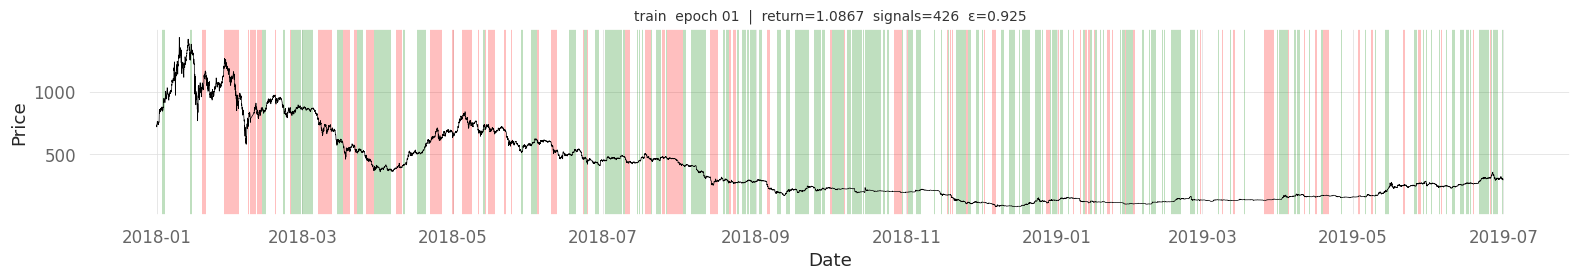

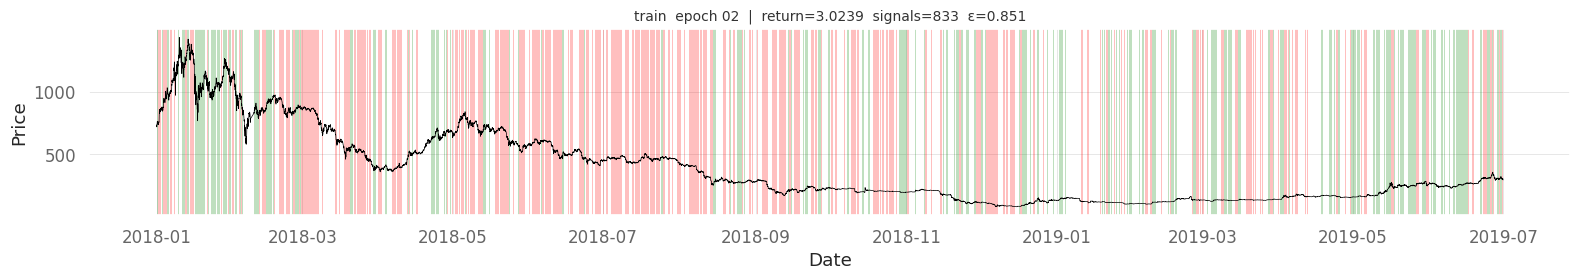

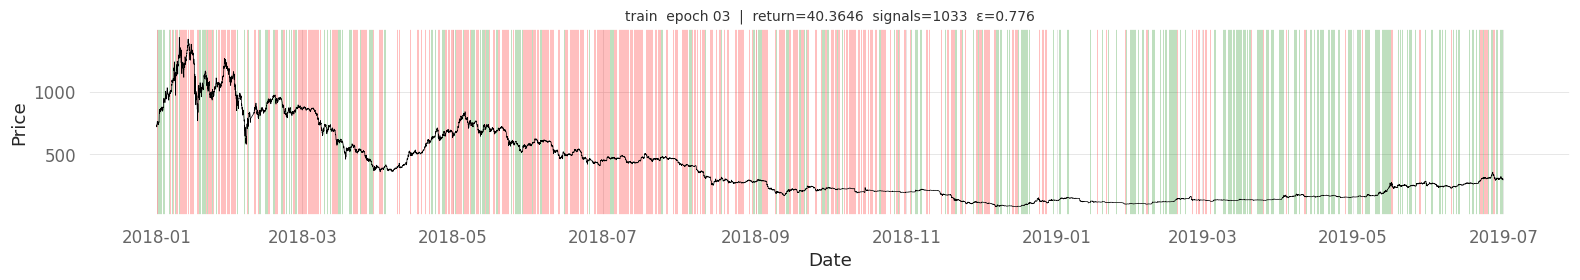

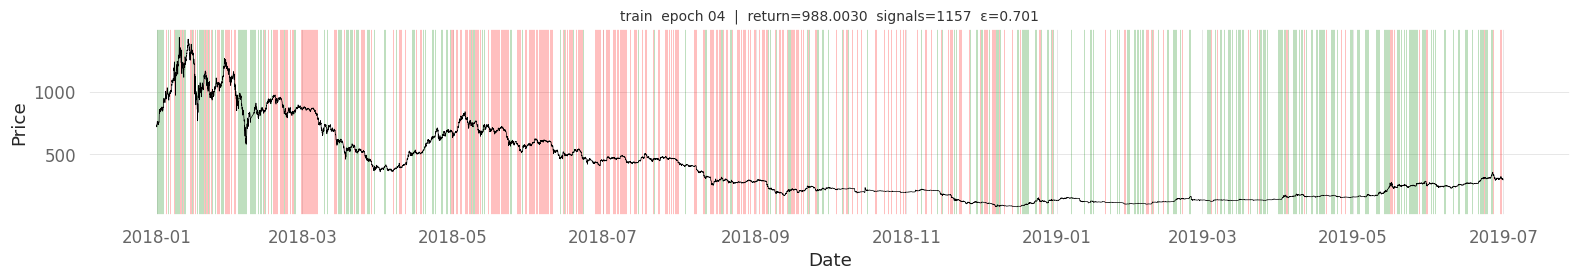

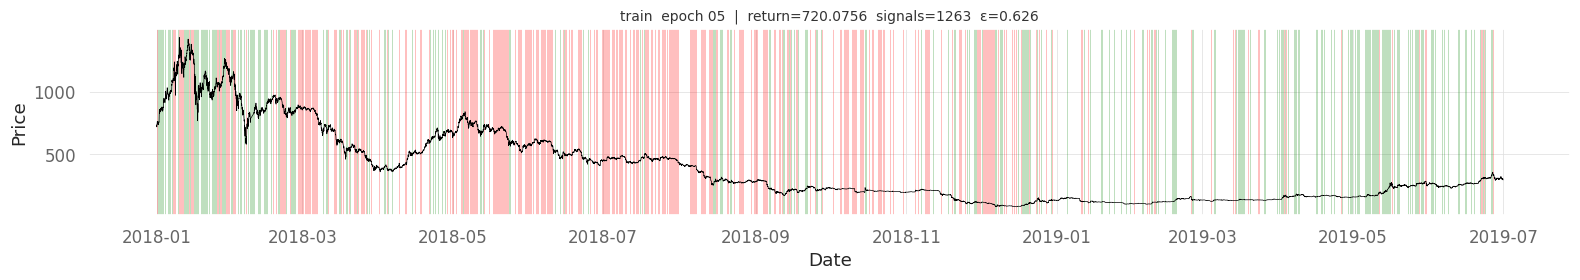

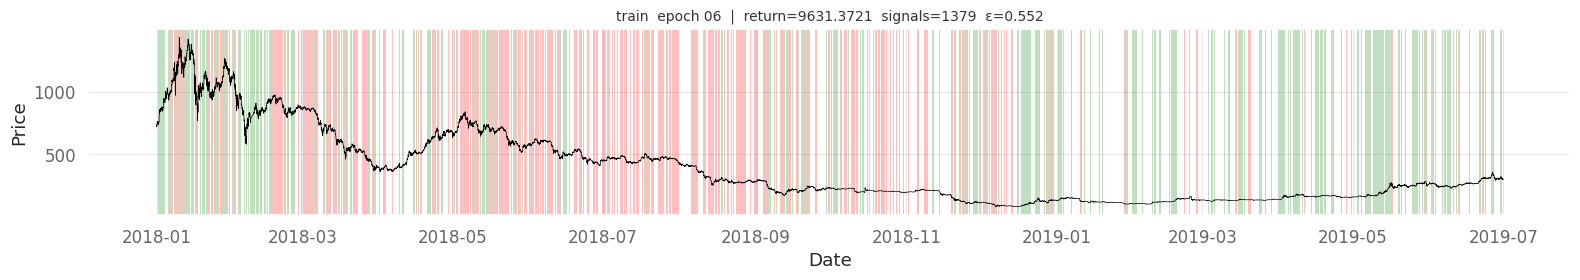

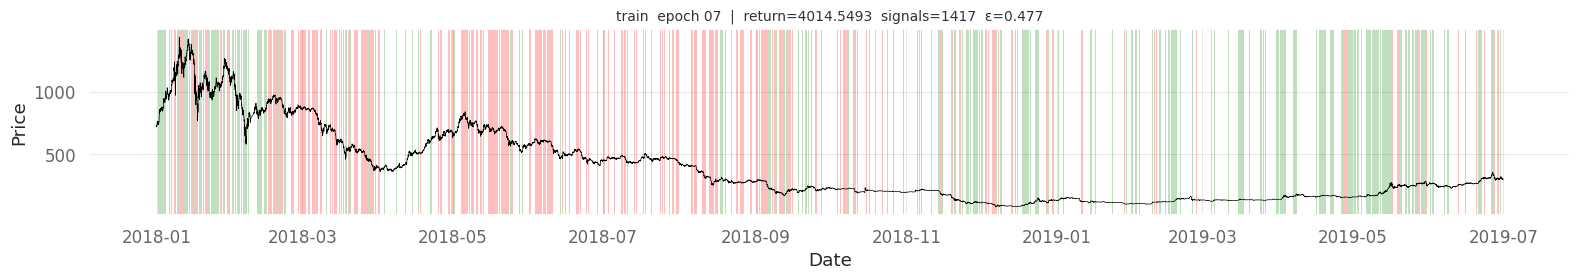

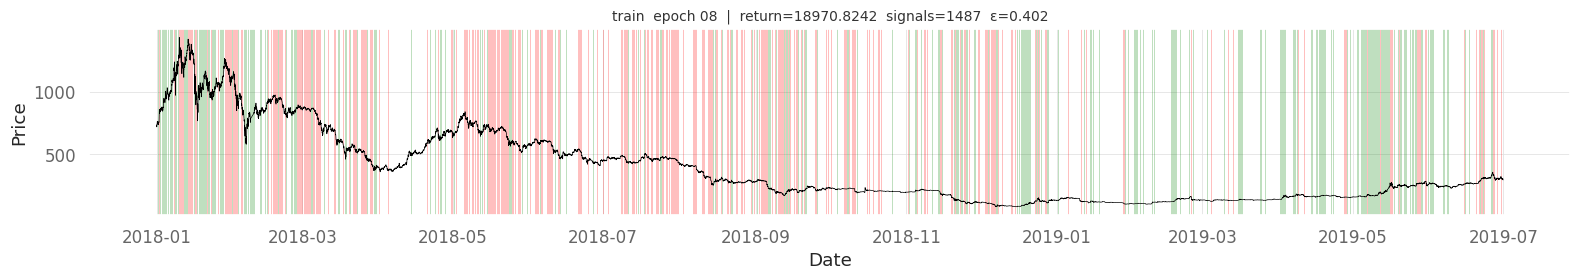

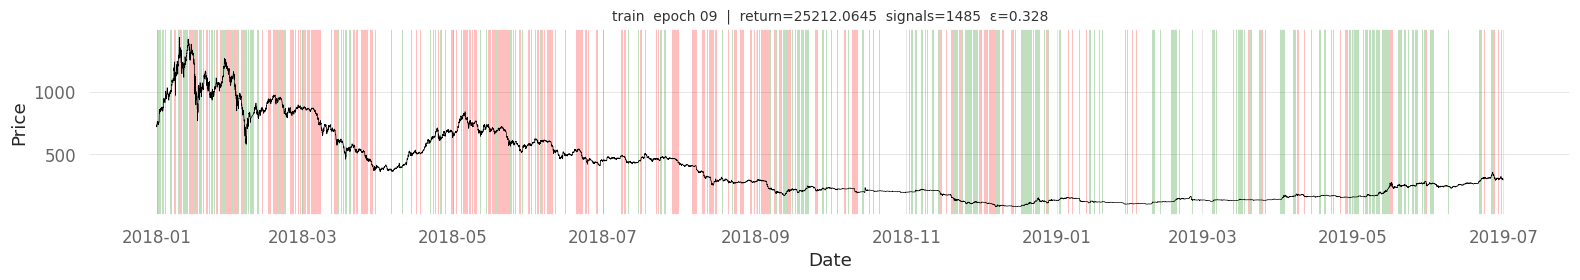

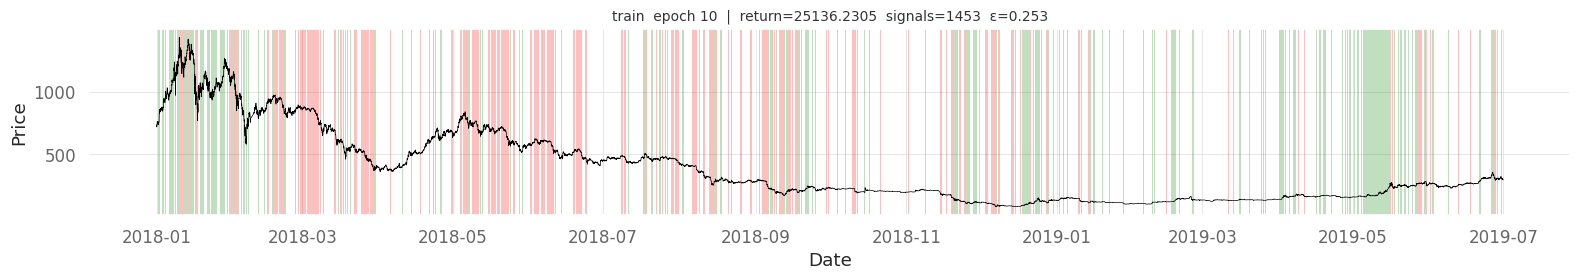

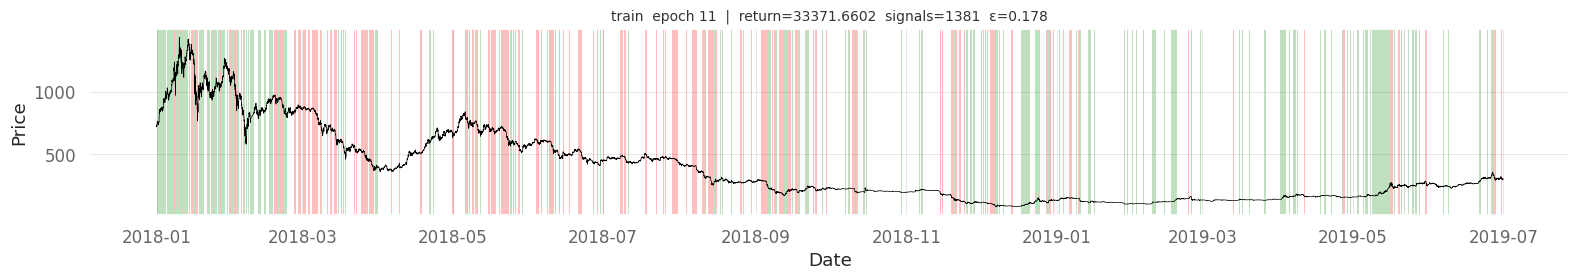

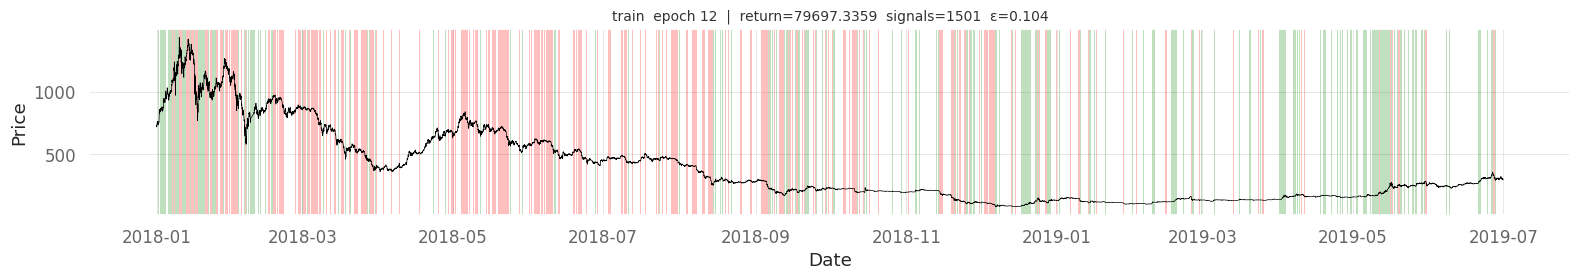

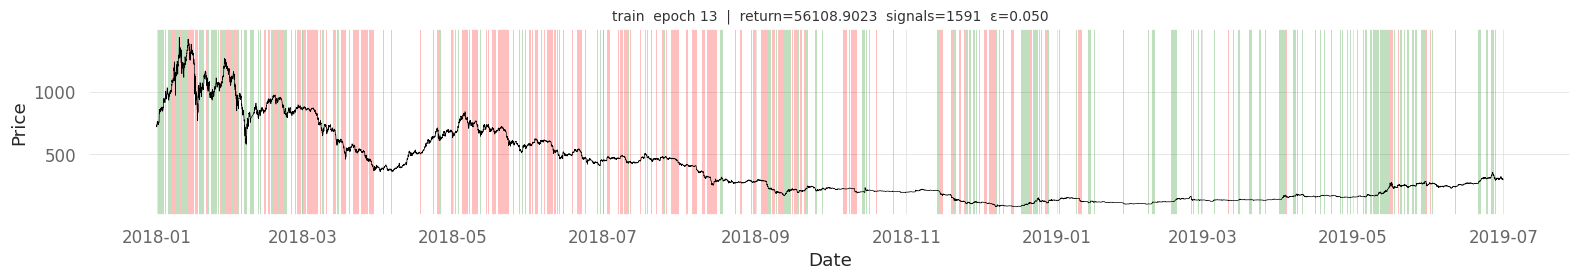

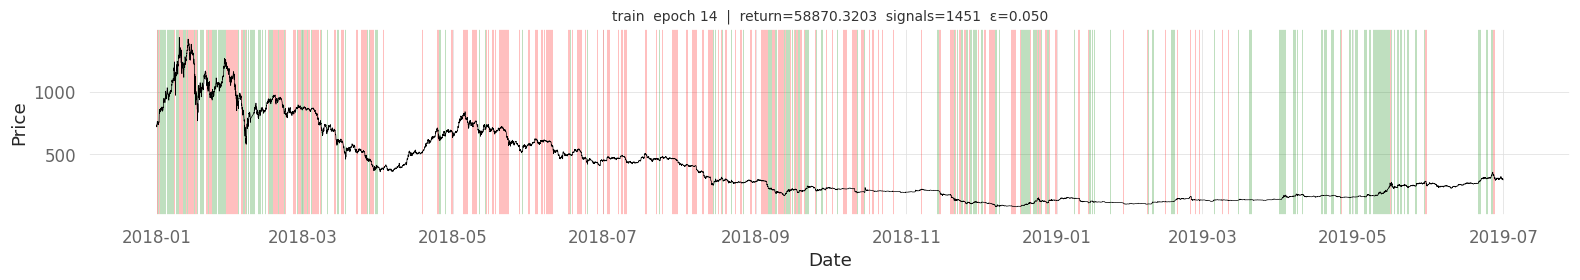

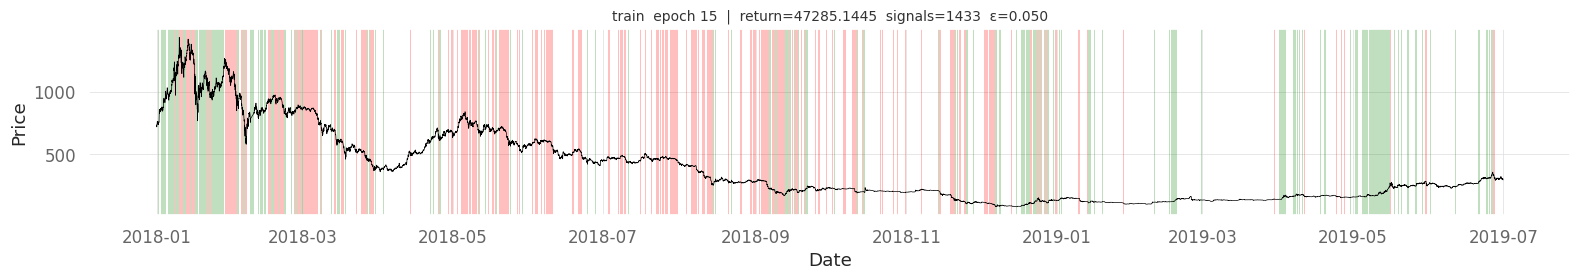

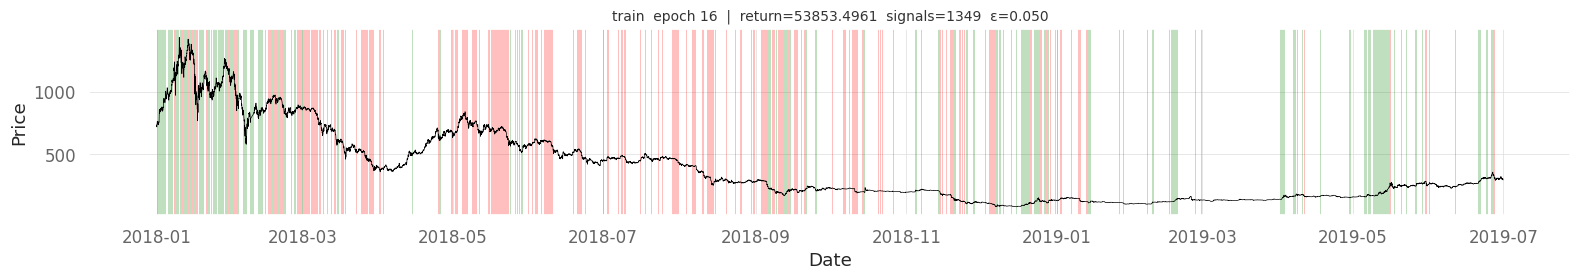

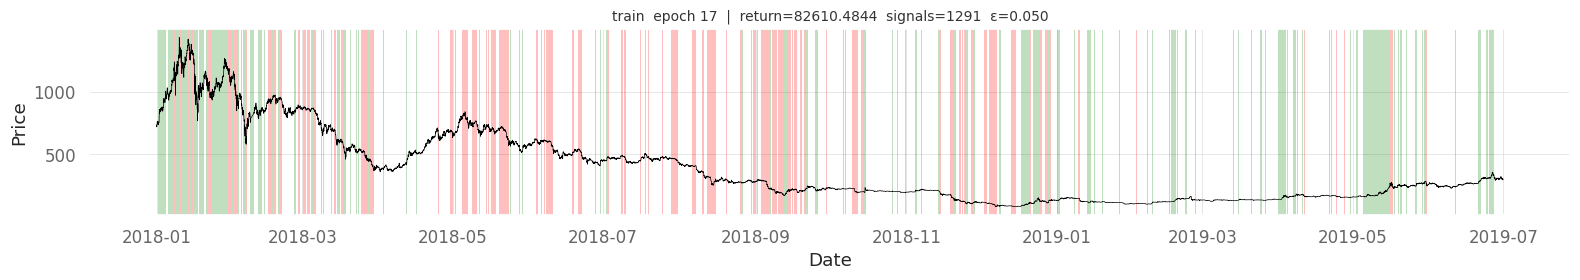

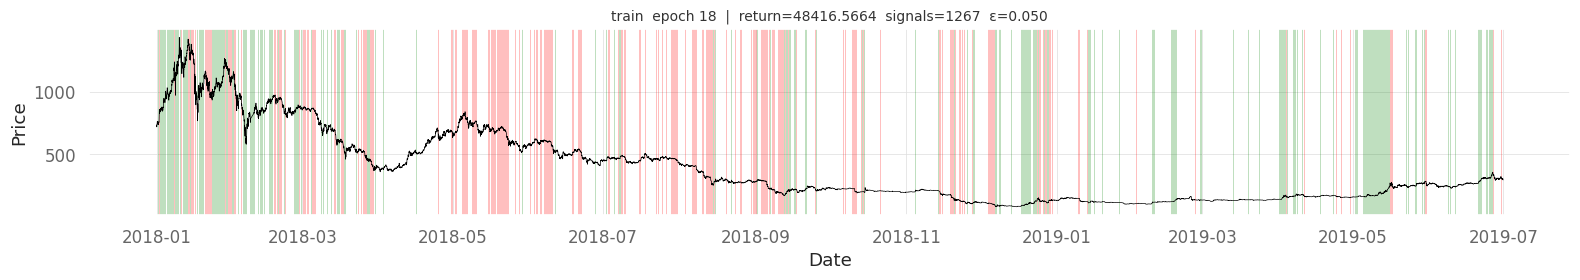

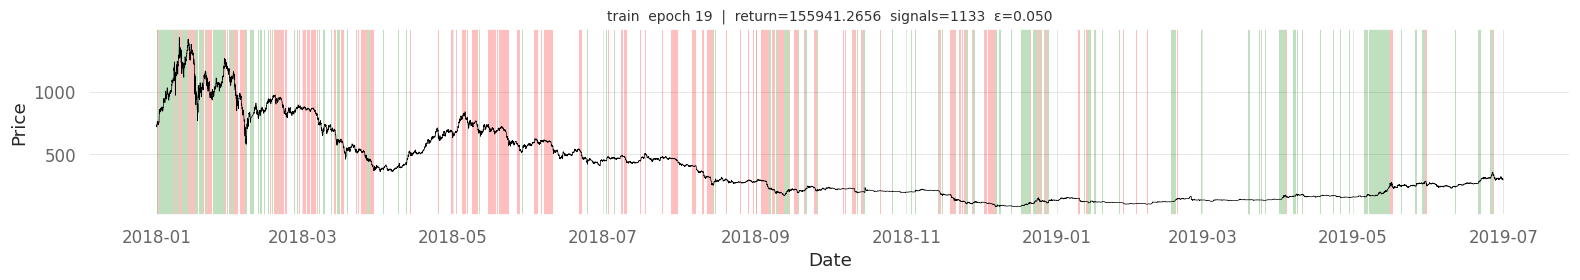

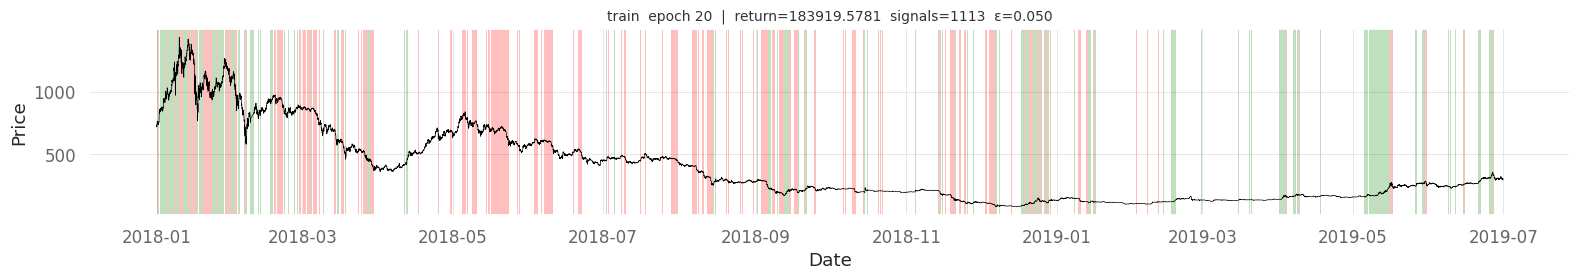

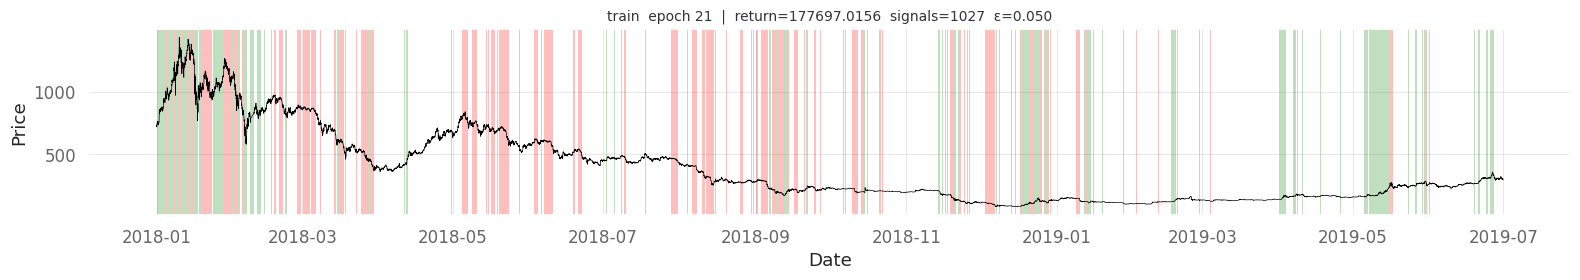

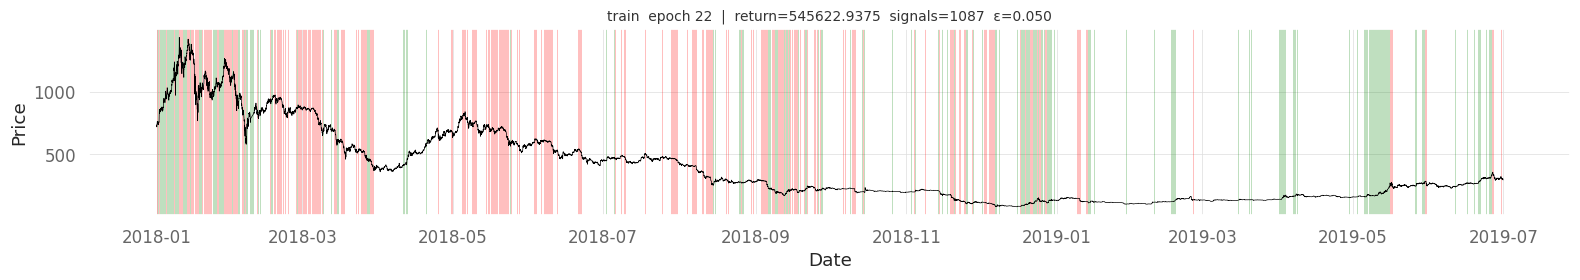

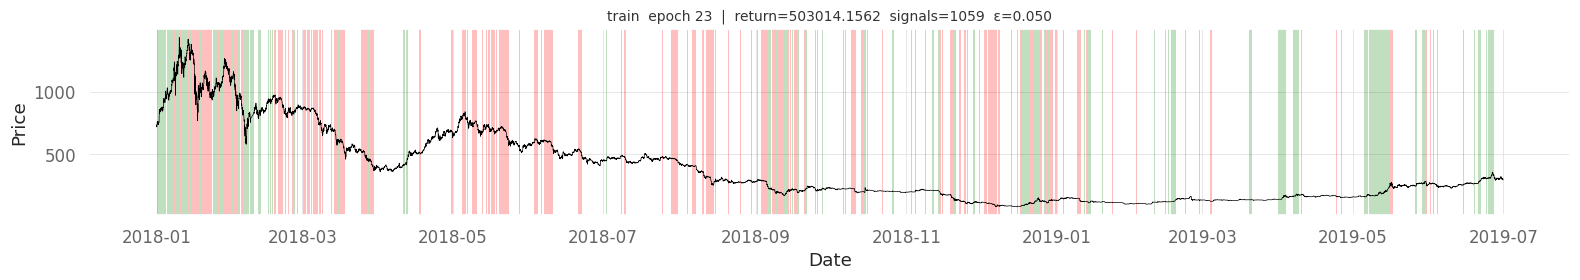

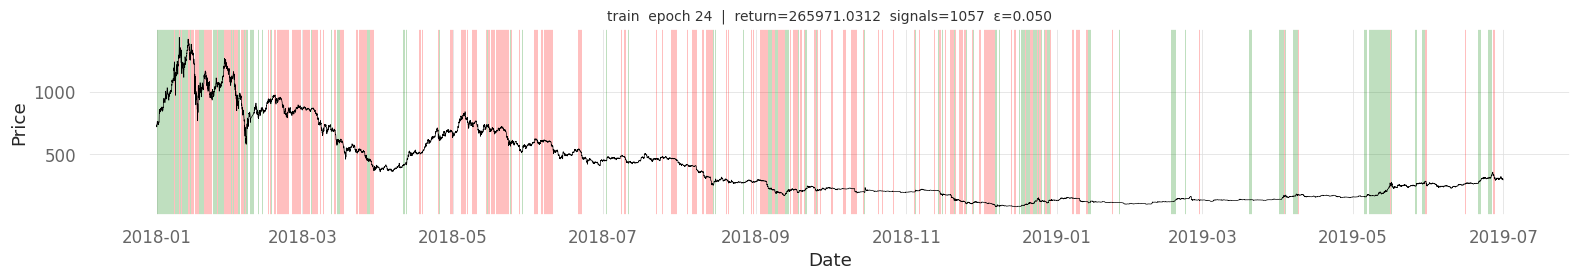

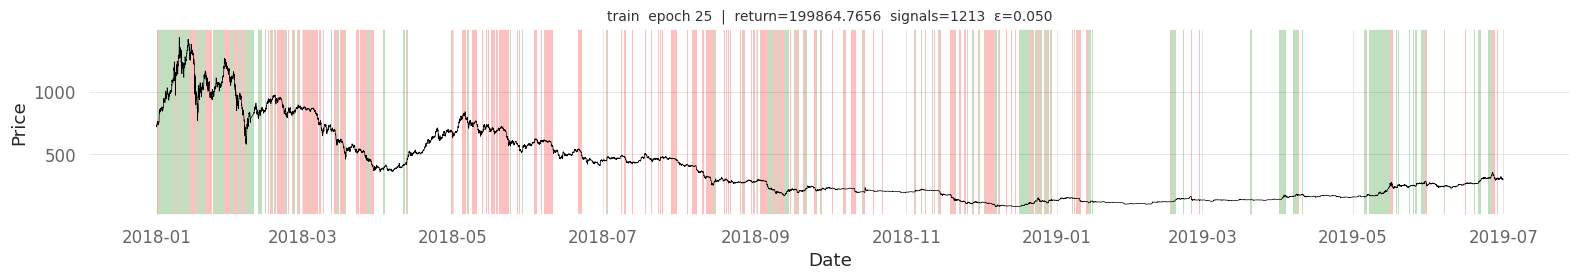

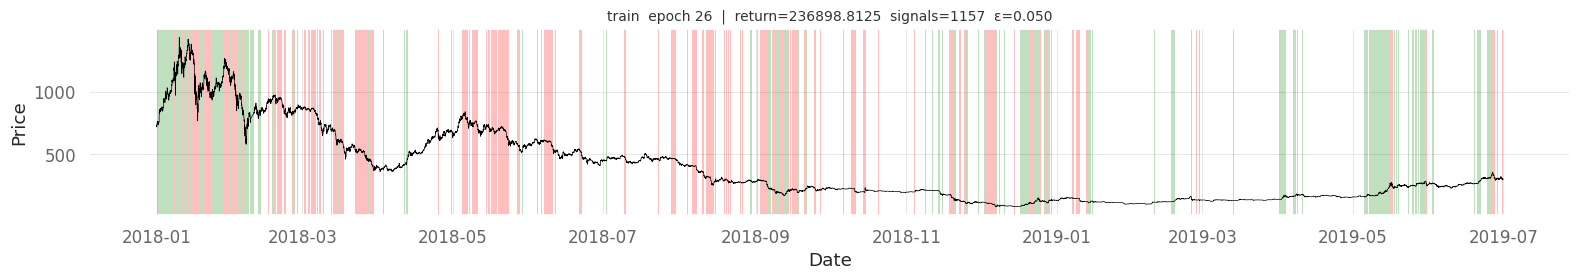

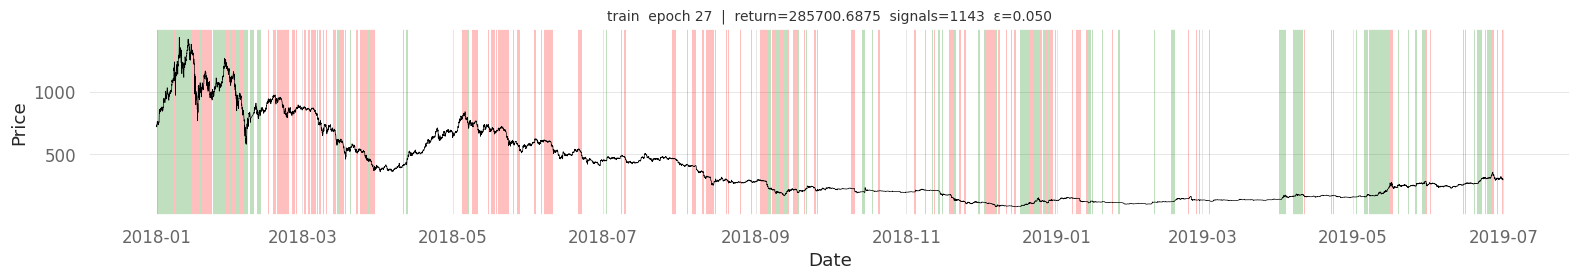

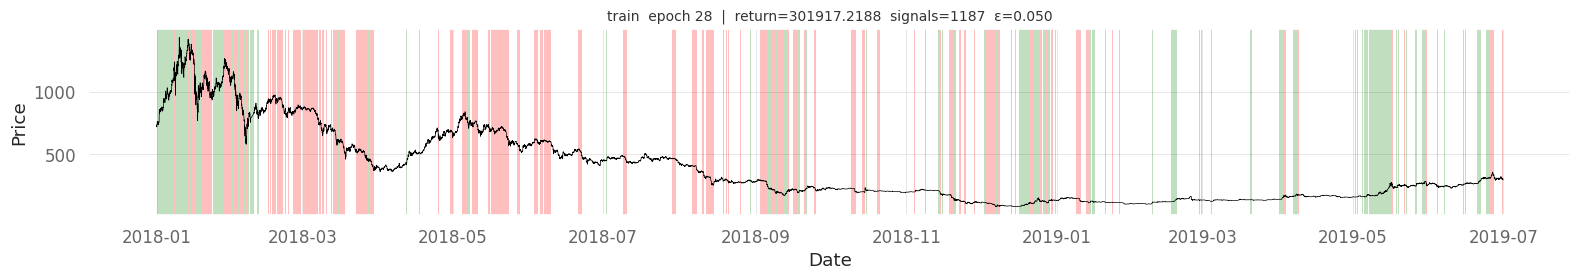

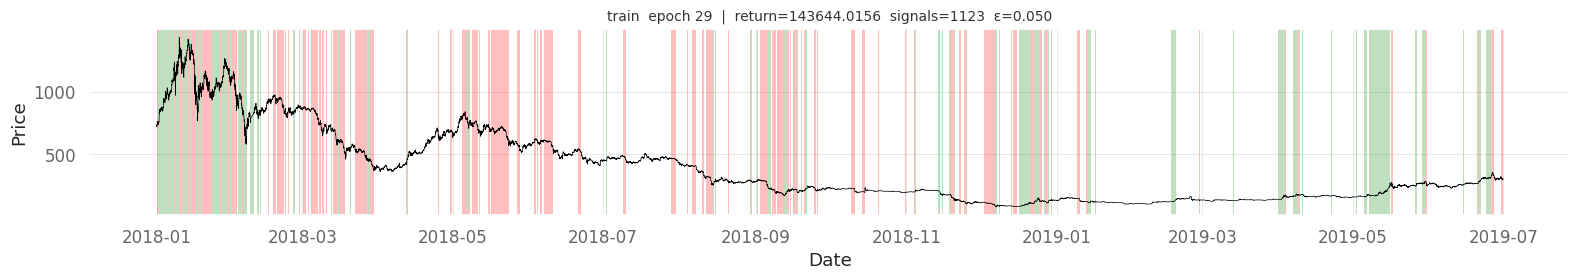

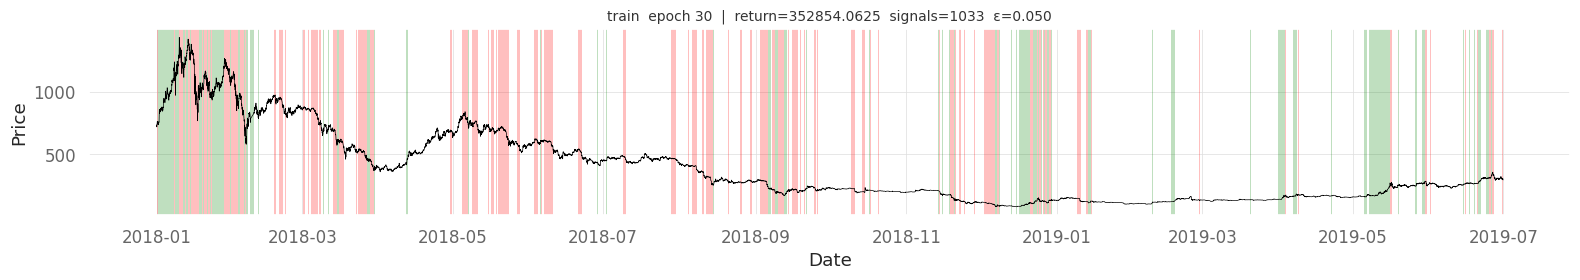

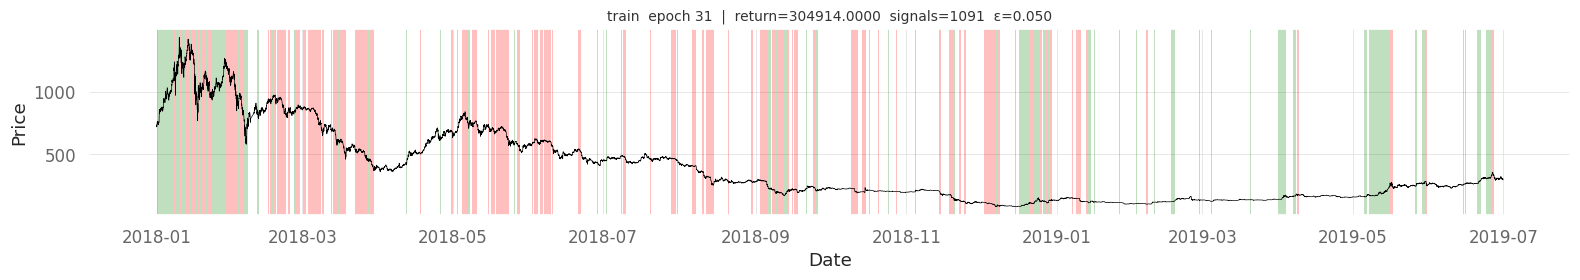

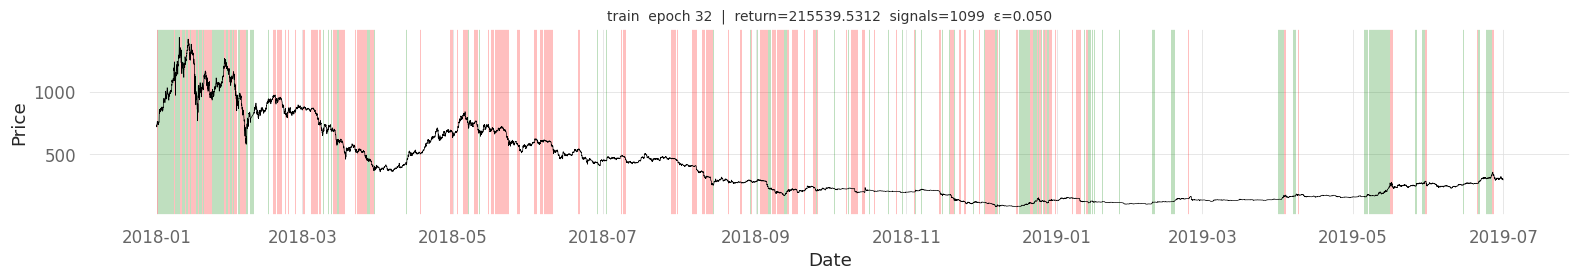

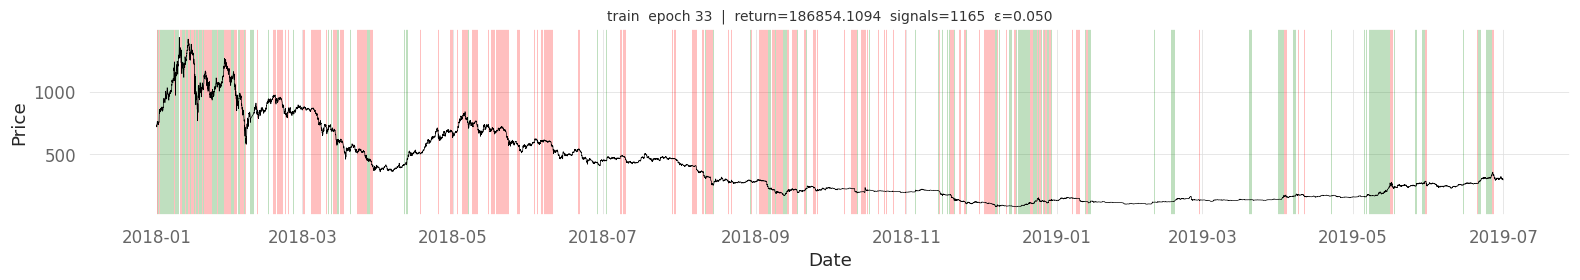

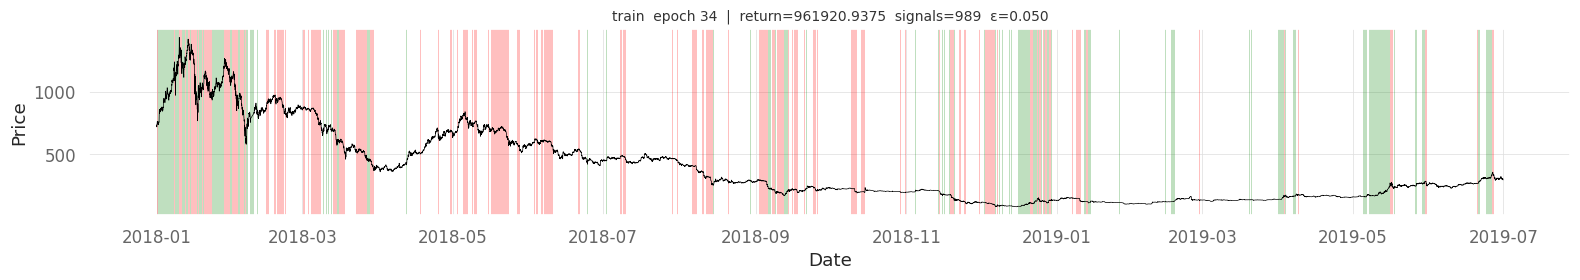

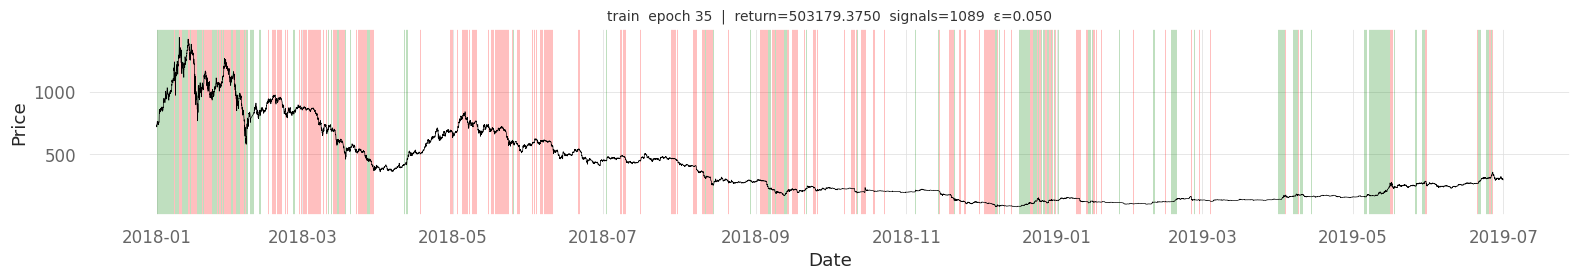

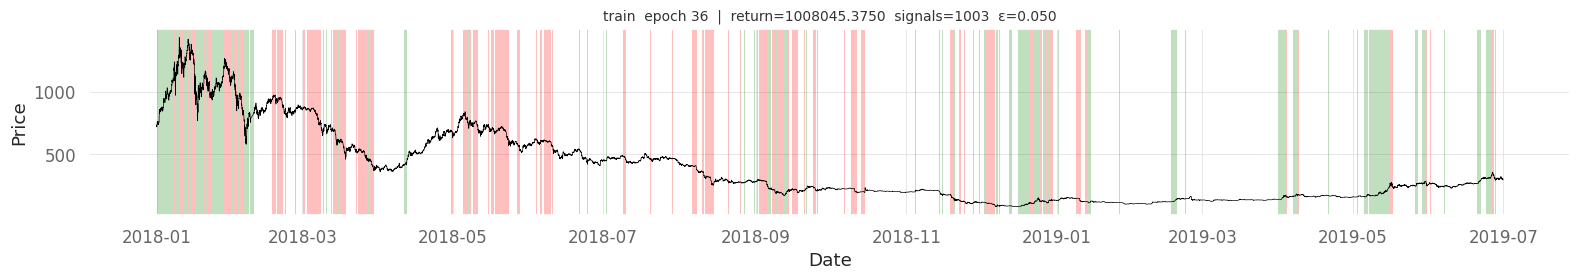

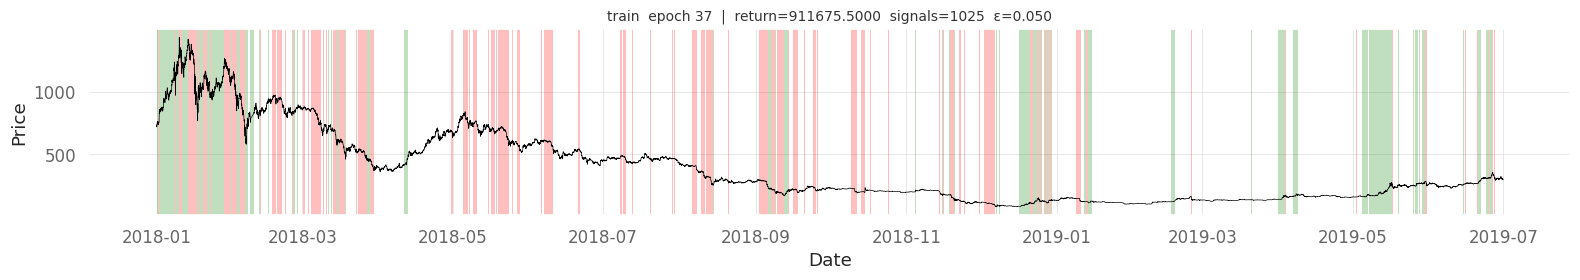

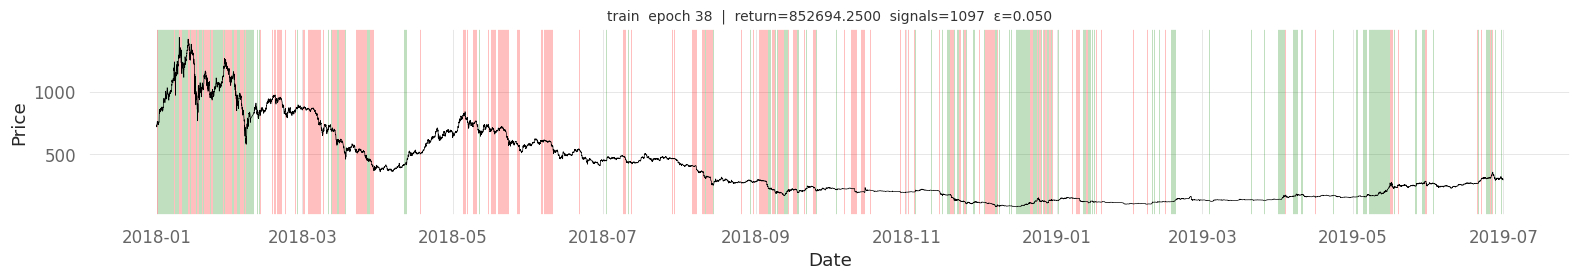

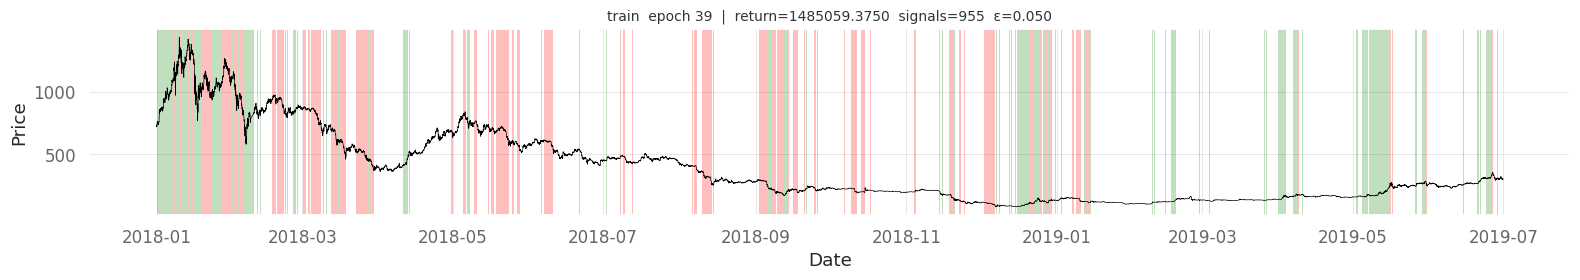

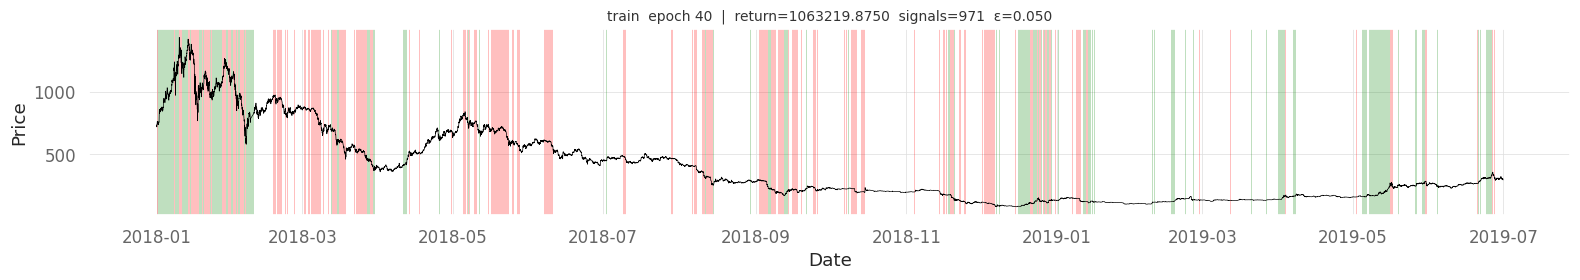

In [19]:
# ── baseline run — DQN with default kwargs, 40 epochs ────────────────────────
# StickyDQN is imported above; switch `DQN` → `StickyDQN` and uncomment
# mean_hold / switching_cost in DEFAULT_KWARGS when ready.

model = StickyDQN(
    env = norm_train_env,
    **DEFAULT_KWARGS,
    **best_params_to_kwargs(study.best_params)
)
N_EPOCHS = 40
model.learn(
    total_timesteps     = N_EPOCHS * train_env.T,
    callback            = PlotCallback(train_env, title_prefix="train"),
    reset_num_timesteps = True,
    progress_bar        = True,
)

In [20]:
# ── val evaluation after training ─────────────────────────────────────────────
ep_val, act_val = deterministic_rollout(norm_val_env, val_env)

price   = price_series_from_env(val_env)
periods = infer_periods(price)
equity  = activity_to_equity(act_val, price)
returns = activity_to_returns(act_val, price)
m       = metrics(returns, equity, periods)

print("── val metrics ──────────────────────────────")
pd.Series(m).round(4)

── val metrics ──────────────────────────────


sharpe          -2.4193
sortino         -3.2569
calmar          -1.4500
cagr            -0.7518
max_drawdown    -0.9518
volatility       0.5196
omega            0.8934
profit_factor    0.8934
win_rate         0.4577
var_95          -0.0093
dtype: float64

2019-06-30 23:00:00    10000.000000
2019-07-01 00:00:00    10000.000000
2019-07-01 01:00:00    10000.000000
2019-07-01 02:00:00    10000.000000
2019-07-01 03:00:00    10000.000000
                           ...     
2019-12-30 18:00:00     4938.936523
2019-12-30 19:00:00     4940.065430
2019-12-30 20:00:00     4958.122559
2019-12-30 21:00:00     4966.398438
2019-12-30 22:00:00     4985.583984
Name: equity, Length: 4380, dtype: float32